<a href="https://colab.research.google.com/github/anshikalittle114-lab/-Integrating-Differential-Gene-Expression-and-Machine-Learning-for-Breast-Cancer-Biomarker-Discovery/blob/main/ML_on_BREAST_CANCER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [88]:
# Breast Cancer Gene Expression Analysis using Machine Learning

# Author: Your Name
# Project: Breast Cancer Biomarker Discovery
# Data: Public transcriptomic data
# Analysis: DESeq2 + Machine Learning

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [90]:
data = pd.read_csv("BreastCancer_ML_55DEG_log2CPM_normalized-1.csv")

data.head()

,Sample,Group,ENSG00000167080,ENSG00000302531,ENSG00000241098,ENSG00000295072,ENSG00000270372,ENSG00000070886,ENSG00000119973,ENSG00000293394,...,ENSG00000302430,ENSG00000168334,ENSG00000101057,ENSG00000172061,ENSG00000301439,ENSG00000111331,ENSG00000138696,ENSG00000233639,ENSG00000308563,ENSG00000287336
0,SRR23912946,Tumor,0.000000,0.000000,0.206831,0.443271,0.0,0.036597,0.0,0.0,...,0.0,0.470277,2.841171,8.246258,0.415750,5.323781,9.179753,0.00000,0.359081,0.359081
1,SRR23912948,Tumor,0.000000,0.645989,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.248864,5.594242,0.432581,5.736398,2.478270,0.07559,0.038290,0.000000
2,SRR23912950,Tumor,0.784772,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.578051,2.945329,3.431746,0.298644,6.951644,8.460756,0.00000,0.000000,0.965550
3,SRR23912952,Tumor,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.761850,3.068916,7.897212,0.000000,6.048214,1.984250,0.00000,0.935881,0.000000
4,SRR23912954,Tumor,2.644840,3.554947,2.838012,2.271632,0.0,0.000000,0.0,0.0,...,0.0,3.999000,3.999000,6.755971,0.723945,9.493931,8.344354,0.00000,1.125116,0.267420


In [91]:
# check dataset
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nGroup distribution:")
print(data["Group"].value_counts())

Dataset shape: (18, 57)

Columns:
['Sample', 'Group', 'ENSG00000167080', 'ENSG00000302531', 'ENSG00000241098', 'ENSG00000295072', 'ENSG00000270372', 'ENSG00000070886', 'ENSG00000119973', 'ENSG00000293394', 'ENSG00000147256', 'ENSG00000260678', 'ENSG00000290981', 'ENSG00000178171', 'ENSG00000299417', 'ENSG00000179796', 'ENSG00000273091', 'ENSG00000259512', 'ENSG00000060718', 'ENSG00000240666', 'ENSG00000105388', 'ENSG00000232528', 'ENSG00000232316', 'ENSG00000244757', 'ENSG00000266846', 'ENSG00000089199', 'ENSG00000290531', 'ENSG00000249375', 'ENSG00000261327', 'ENSG00000308375', 'ENSG00000299988', 'ENSG00000254707', 'ENSG00000249001', 'ENSG00000271401', 'ENSG00000197272', 'ENSG00000130477', 'ENSG00000278311', 'ENSG00000308795', 'ENSG00000175779', 'ENSG00000101082', 'ENSG00000102981', 'ENSG00000270883', 'ENSG00000254192', 'ENSG00000297058', 'ENSG00000152591', 'ENSG00000251141', 'ENSG00000204257', 'ENSG00000302430', 'ENSG00000168334', 'ENSG00000101057', 'ENSG00000172061', 'ENSG0000030143

In [92]:
# X= genes/feature
#Y= tumor/normal
X = data.drop(columns=["Sample", "Group"])

y = data["Group"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (18, 55)
y shape: (18,)


In [93]:
# convert tumor/normal ko 0/1
y = y.map({
    "Normal": 0,
    "Tumor": 1
})

print(y)

0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
Name: Group, dtype: int64


In [94]:
# check data
print("Missing values:", X.isnull().sum().sum())
print("Infinite values:", np.isinf(X.values).sum())

Missing values: 0
Infinite values: 0


In [95]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [96]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

In [97]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [98]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation is ready.")

5-Fold Stratified Cross-Validation is ready.


In [99]:
logistic_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy of each fold:")
print(logistic_scores)

print("\nMean Accuracy:",
      logistic_scores.mean())

print("Standard Deviation:",
      logistic_scores.std())

Accuracy of each fold:
[1. 1. 1. 1. 1.]

Mean Accuracy: 1.0
Standard Deviation: 0.0


In [100]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

# Cross-validated predictions
y_pred = cross_val_predict(
    logistic_model,
    X,
    y,
    cv=cv
)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y, y_pred))

Confusion Matrix:
[[9 0]
 [0 9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00         9

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



ROC-AUC: 1.0


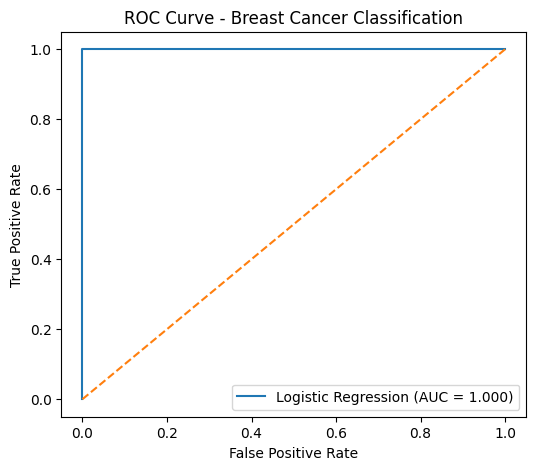

In [101]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability predictions using cross-validation
y_prob = cross_val_predict(
    logistic_model,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(y, y_prob)

# AUC
auc_score = roc_auc_score(y, y_prob)

print("ROC-AUC:", auc_score)

# Plot ROC curve
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Breast Cancer Classification")
plt.legend()
plt.show()

In [102]:
print("Dataset shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

Dataset shape: (18, 57)

Columns:
['Sample', 'Group', 'ENSG00000167080', 'ENSG00000302531', 'ENSG00000241098', 'ENSG00000295072', 'ENSG00000270372', 'ENSG00000070886', 'ENSG00000119973', 'ENSG00000293394', 'ENSG00000147256', 'ENSG00000260678', 'ENSG00000290981', 'ENSG00000178171', 'ENSG00000299417', 'ENSG00000179796', 'ENSG00000273091', 'ENSG00000259512', 'ENSG00000060718', 'ENSG00000240666', 'ENSG00000105388', 'ENSG00000232528', 'ENSG00000232316', 'ENSG00000244757', 'ENSG00000266846', 'ENSG00000089199', 'ENSG00000290531', 'ENSG00000249375', 'ENSG00000261327', 'ENSG00000308375', 'ENSG00000299988', 'ENSG00000254707', 'ENSG00000249001', 'ENSG00000271401', 'ENSG00000197272', 'ENSG00000130477', 'ENSG00000278311', 'ENSG00000308795', 'ENSG00000175779', 'ENSG00000101082', 'ENSG00000102981', 'ENSG00000270883', 'ENSG00000254192', 'ENSG00000297058', 'ENSG00000152591', 'ENSG00000251141', 'ENSG00000204257', 'ENSG00000302430', 'ENSG00000168334', 'ENSG00000101057', 'ENSG00000172061', 'ENSG0000030143

In [103]:
print("\nFirst 5 rows:")
display(data.head())


First 5 rows:


,Sample,Group,ENSG00000167080,ENSG00000302531,ENSG00000241098,ENSG00000295072,ENSG00000270372,ENSG00000070886,ENSG00000119973,ENSG00000293394,...,ENSG00000302430,ENSG00000168334,ENSG00000101057,ENSG00000172061,ENSG00000301439,ENSG00000111331,ENSG00000138696,ENSG00000233639,ENSG00000308563,ENSG00000287336
0,SRR23912946,Tumor,0.000000,0.000000,0.206831,0.443271,0.0,0.036597,0.0,0.0,...,0.0,0.470277,2.841171,8.246258,0.415750,5.323781,9.179753,0.00000,0.359081,0.359081
1,SRR23912948,Tumor,0.000000,0.645989,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.248864,5.594242,0.432581,5.736398,2.478270,0.07559,0.038290,0.000000
2,SRR23912950,Tumor,0.784772,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.578051,2.945329,3.431746,0.298644,6.951644,8.460756,0.00000,0.000000,0.965550
3,SRR23912952,Tumor,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.761850,3.068916,7.897212,0.000000,6.048214,1.984250,0.00000,0.935881,0.000000
4,SRR23912954,Tumor,2.644840,3.554947,2.838012,2.271632,0.0,0.000000,0.0,0.0,...,0.0,3.999000,3.999000,6.755971,0.723945,9.493931,8.344354,0.00000,1.125116,0.267420


In [104]:
# random forest model
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

# 5-fold stratified cross-validation
rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Random Forest Accuracy of each fold:")
print(rf_scores)

print("\nMean Accuracy:")
print(rf_scores.mean())

print("\nStandard Deviation:")
print(rf_scores.std())

Random Forest Accuracy of each fold:
[1. 1. 1. 1. 1.]

Mean Accuracy:
1.0

Standard Deviation:
0.0


Random Forest ROC-AUC: 1.0


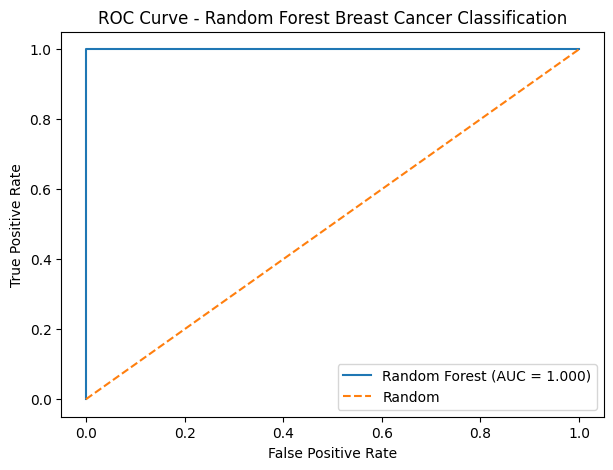

In [105]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Cross-validated probability predictions
rf_prob = cross_val_predict(
    rf_model,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

# ROC-AUC
rf_auc = roc_auc_score(y, rf_prob)

print("Random Forest ROC-AUC:", rf_auc)

# ROC curve
fpr, tpr, thresholds = roc_curve(y, rf_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest Breast Cancer Classification")
plt.legend()
plt.show()

In [106]:
# Train Random Forest on the complete dataset
rf_model.fit(X, y)

# Get feature importance
importance = rf_model.feature_importances_

# Create feature-importance table
feature_importance = pd.DataFrame({
    "Gene": X.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Show top 20 genes
print("Top 20 Important Genes:")
display(feature_importance.head(20))

Top 20 Important Genes:


,Gene,Importance
13,ENSG00000179796,0.083817
22,ENSG00000266846,0.081144
49,ENSG00000301439,0.073580
27,ENSG00000308375,0.068353
14,ENSG00000273091,0.060967
17,ENSG00000240666,0.055121
25,ENSG00000249375,0.050947
26,ENSG00000261327,0.046661
52,ENSG00000233639,0.037470
32,ENSG00000197272,0.036873


In [107]:
# ==========================================
# RANDOM FOREST + FEATURE IMPORTANCE
# ==========================================

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# Ensure data, X, and y are defined
data = pd.read_csv("BreastCancer_ML_55DEG_log2CPM_normalized-1.csv")
X = data.drop(columns=["Sample", "Group"])
y = data["Group"]
y = y.map({"Normal": 0, "Tumor": 1})

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

rf_model.fit(X, y)

# Get feature importance
importance = rf_model.feature_importances_

# Create feature importance table
feature_importance = pd.DataFrame({
    "Gene": X.columns,
    "Importance": importance
})

# Sort highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Show top 20 genes
print("Top 20 Important Genes:")
display(feature_importance.head(20))

Top 20 Important Genes:


,Gene,Importance
13,ENSG00000179796,0.083817
22,ENSG00000266846,0.081144
49,ENSG00000301439,0.073580
27,ENSG00000308375,0.068353
14,ENSG00000273091,0.060967
17,ENSG00000240666,0.055121
25,ENSG00000249375,0.050947
26,ENSG00000261327,0.046661
52,ENSG00000233639,0.037470
32,ENSG00000197272,0.036873


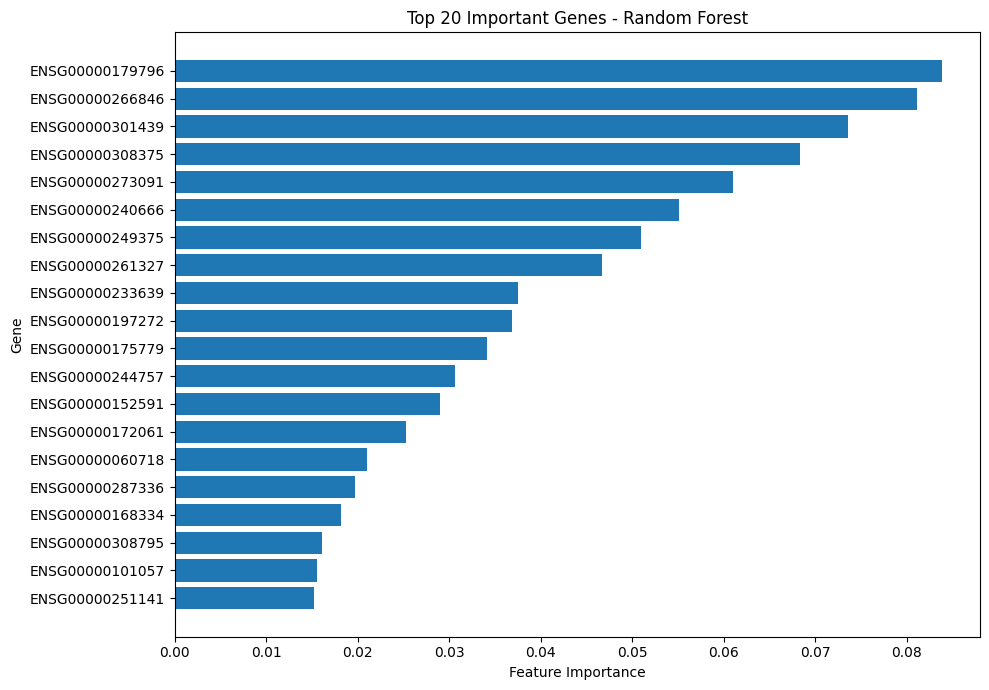

In [108]:
# ==========================================
# TOP 20 IMPORTANT GENES – BAR PLOT
# ==========================================

top20 = feature_importance.head(20)

plt.figure(figsize=(10, 7))

plt.barh(
    top20["Gene"],
    top20["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Gene")
plt.title("Top 20 Important Genes - Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [109]:
# ==========================================
# LOGISTIC REGRESSION vs RANDOM FOREST
# 5-FOLD CROSS-VALIDATION COMPARISON
# ==========================================

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Random Forest
rf_model_comparison = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

# Cross-validation scores
logistic_cv = cross_val_score(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

rf_cv = cross_val_score(
    rf_model_comparison,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

# Create comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Mean CV Accuracy": [
        logistic_cv.mean(),
        rf_cv.mean()
    ],
    "Standard Deviation": [
        logistic_cv.std(),
        rf_cv.std()
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison)

print("Logistic Regression fold accuracies:", logistic_cv)
print("Random Forest fold accuracies:", rf_cv)

MODEL PERFORMANCE COMPARISON


,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,1.0,0.0
1,Random Forest,1.0,0.0


Logistic Regression fold accuracies: [1. 1. 1. 1. 1.]
Random Forest fold accuracies: [1. 1. 1. 1. 1.]


In [111]:
print("Dataset shape:", data.shape)
print("\nGroup counts:")
print(data["Group"].value_counts())

Dataset shape: (18, 57)

Group counts:
Group
Tumor     9
Normal    9
Name: count, dtype: int64


In [112]:
print(data.columns.tolist())

['Sample', 'Group', 'ENSG00000167080', 'ENSG00000302531', 'ENSG00000241098', 'ENSG00000295072', 'ENSG00000270372', 'ENSG00000070886', 'ENSG00000119973', 'ENSG00000293394', 'ENSG00000147256', 'ENSG00000260678', 'ENSG00000290981', 'ENSG00000178171', 'ENSG00000299417', 'ENSG00000179796', 'ENSG00000273091', 'ENSG00000259512', 'ENSG00000060718', 'ENSG00000240666', 'ENSG00000105388', 'ENSG00000232528', 'ENSG00000232316', 'ENSG00000244757', 'ENSG00000266846', 'ENSG00000089199', 'ENSG00000290531', 'ENSG00000249375', 'ENSG00000261327', 'ENSG00000308375', 'ENSG00000299988', 'ENSG00000254707', 'ENSG00000249001', 'ENSG00000271401', 'ENSG00000197272', 'ENSG00000130477', 'ENSG00000278311', 'ENSG00000308795', 'ENSG00000175779', 'ENSG00000101082', 'ENSG00000102981', 'ENSG00000270883', 'ENSG00000254192', 'ENSG00000297058', 'ENSG00000152591', 'ENSG00000251141', 'ENSG00000204257', 'ENSG00000302430', 'ENSG00000168334', 'ENSG00000101057', 'ENSG00000172061', 'ENSG00000301439', 'ENSG00000111331', 'ENSG000001

In [113]:
print(data["Group"].value_counts())

Group
Tumor     9
Normal    9
Name: count, dtype: int64


In [114]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["Sample", "Group"])
y = data["Group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 14
Testing samples: 4


In [115]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=5000)
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [116]:
from sklearn.metrics import accuracy_score

y_pred = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

Test Accuracy: 1.0


In [118]:
y_test_numeric = y_test.map({"Normal": 0, "Tumor": 1})
rf_test_accuracy = rf_model.score(X_test, y_test_numeric)

print("Random Forest Test Accuracy:", rf_test_accuracy)

Random Forest Test Accuracy: 1.0


In [119]:
from sklearn.metrics import classification_report, confusion_matrix

print("Logistic Regression")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Logistic Regression
[[2 0]
 [0 2]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
       Tumor       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [120]:
from sklearn.metrics import classification_report, confusion_matrix

print("Logistic Regression")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Logistic Regression
[[2 0]
 [0 2]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
       Tumor       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [124]:
y_test_encoded = y_test.map({"Normal": 0, "Tumor": 1})

print("Random Forest")
print(confusion_matrix(y_test_encoded, rf_pred))
print(classification_report(y_test_encoded, rf_pred))

Random Forest
[[2 0]
 [0 2]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [125]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Test Accuracy": [
        (y_pred == y_test).mean(),
        (rf_pred == y_test_encoded).mean()
    ]
})

display(comparison)

,Model,Test Accuracy
0,Logistic Regression,1.0
1,Random Forest,1.0
